# 02 : FinBERT contre Jev sur les posts d'Elon Musk à propos de Tesla

**Question :** lequel des deux modèles lit le mieux les posts de Musk, au sens où son verdict annonce
la réaction de l'action Tesla dans les minutes qui suivent ?

| | FinBERT | Jev |
|---|---|---|
| Nature | BERT entraîné sur des phrases de presse financière | Modèle hébergé par TypeSafe, sans génération de texte |
| Sortie | positive / negative / neutral | Une probabilité par option, options choisies librement |
| Exécution | Local (CPU), gratuit | API payante (environ 0,04 $ par million de tokens) |

Jev reçoit trois questions dans le même appel :
- `sentiment` : la même question que FinBERT (positive / negative / neutral), pour comparer à armes égales ;
- `impact` : l'effet attendu sur TSLA à court terme (up / down / none), la question qui intéresse vraiment le projet ;
- `relevant` : probabilité que le post puisse faire bouger TSLA.

**Comparaisons :**
1. accord entre les deux modèles ;
2. capacité à annoncer la réaction de TSLA (rendement anormal par rapport à QQQ) à +1, +5, +15 et +60 minutes ;
3. latence et coût.

**Précautions à garder en tête :**
- Il n'y a pas d'étiquettes humaines : la « vérité » utilisée est la réaction du marché, qui est très bruitée.
- FinBERT a été entraîné sur de la presse financière, pas sur des tweets.
- Jev a pu être entraîné sur des textes postérieurs à 2018-2024 : il peut « savoir » comment le marché a réagi
  (fuite d'information). Un bon score de Jev doit donc être interprété avec prudence.
- Musk publie beaucoup : plusieurs posts peuvent tomber dans la même fenêtre et brouiller la mesure.

Prérequis : avoir exécuté `01_collecte_donnees.ipynb`.

In [1]:
import sys
from pathlib import Path

# Le notebook peut être lancé depuis la racine du projet ou depuis notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

import collect
from collect import DATA

DATA.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)
import time

import numpy as np
from scipy import stats
from sklearn.metrics import cohen_kappa_score

import sentiment
from timeutils import session_of

## 1. Sélection des posts

Posts de 2018-2024 qui mentionnent Tesla (filtre par mots-clés de `collect.mentions_tesla`), hors retweets.
Les liens sont retirés du texte avant la classification.

In [2]:
KINDS = ["original", "quote", "reply"]

posts = pd.read_parquet(DATA / "musk_posts.parquet")
posts = posts[posts.ts_utc.dt.year.between(2018, 2024) & posts.kind.isin(KINDS)]
posts = posts[collect.mentions_tesla(posts.text)].copy()
posts["clean_text"] = (posts.text.str.replace(r"https?://\S+", "", regex=True)
                       .str.replace(r"\s+", " ", regex=True).str.strip())
posts = posts[posts.clean_text.str.len() > 0].reset_index(drop=True)
print(f"{len(posts):,} posts à classer")
posts.kind.value_counts()

2,894 posts à classer


kind
reply       2170
original     535
quote        189
Name: count, dtype: int64

## 2. Classification

Les résultats sont mis en cache dans `data/` : relancer le notebook ne rappelle pas l'API de Jev
pour les posts déjà classés.

In [3]:
def classify_cached(name, df, fn):
    """Classe les posts absents du cache data/<name> avec fn(textes), puis renvoie tout le cache."""
    path = DATA / name
    done = pd.read_parquet(path) if path.exists() else None
    todo = df if done is None else df[~df.id.isin(done.id)]
    if len(todo):
        t0 = time.perf_counter()
        new = fn(todo.clean_text.tolist())
        new.insert(0, "id", todo.id.to_numpy())
        # Les posts en échec (erreur réseau) ne sont pas mis en cache : ils seront retentés au prochain lancement
        failed = new.pop("error").notna() if "error" in new else pd.Series(False, index=new.index)
        print(f"{name} : {(~failed).sum()} posts classés en {time.perf_counter() - t0:.0f} s, {failed.sum()} en échec")
        new = new[~failed]
        done = new if done is None else pd.concat([done, new], ignore_index=True)
        done.to_parquet(path, index=False)
    return done


finbert = classify_cached("finbert_musk_tesla.parquet", posts, sentiment.finbert_classify)
jev = classify_cached("jev_musk_tesla.parquet", posts, sentiment.jev_classify)

df = (posts.merge(finbert.add_prefix("fb_").rename(columns={"fb_id": "id"}), on="id")
      .merge(jev.add_prefix("jev_").rename(columns={"jev_id": "id"}), on="id"))
# Scores dans [-1, 1] : probabilité « positif » moins probabilité « négatif »
df["fb_score"] = df.fb_p_positive - df.fb_p_negative
df["jev_sent_score"] = df.jev_sent_p_positive - df.jev_sent_p_negative
df["jev_impact_score"] = df.jev_impact_p_up - df.jev_impact_p_down
print(f"{len(df):,} posts classés par les deux modèles")

2,894 posts classés par les deux modèles


## 3. Accord entre les deux modèles

Même question posée aux deux : quel est le sentiment financier du post ?
Le kappa de Cohen mesure l'accord en retirant celui dû au hasard (0 : hasard, 1 : accord parfait).

In [4]:
agreement = (df.fb_label == df.jev_sent_label).mean()
kappa = cohen_kappa_score(df.fb_label, df.jev_sent_label)
print(f"Accord : {agreement:.1%}   kappa de Cohen : {kappa:.2f}")
pd.crosstab(df.fb_label.rename("FinBERT"), df.jev_sent_label.rename("Jev"), margins=True)

Accord : 54.6%   kappa de Cohen : 0.20


Jev,negative,neutral,positive,All
FinBERT,,,,
negative,76,48,32,156
neutral,161,1202,1005,2368
positive,17,50,303,370
All,254,1300,1340,2894


In [5]:
# Les désaccords les plus francs : un modèle dit positif, l'autre négatif
clash = df[((df.fb_label == "positive") & (df.jev_sent_label == "negative"))
           | ((df.fb_label == "negative") & (df.jev_sent_label == "positive"))]
print(f"{len(clash)} désaccords francs")
clash[["ts_utc", "clean_text", "fb_label", "jev_sent_label", "jev_impact_label"]].head(15)

49 désaccords francs


,ts_utc,clean_text,fb_label,jev_sent_label,jev_impact_label
53,2018-05-04 12:04:51.246000+00:00,"Reason RBC question about Model 3 demand is absurd is that Tesla has roughly half a million reservations, despite no...",negative,positive,up
85,2018-05-21 07:05:19.873000+00:00,"@dmatkins137 @ShayneRarma @NASA Also, UAW did nada for job security in last recession. Dropped Fremont like a hot po...",negative,positive,up
98,2018-05-22 17:51:32.330000+00:00,"@mikeyfranklin @dmatkins137 @ShayneRarma @NASA More “Reveal” bs. Tesla is overseen by Cal/OSHA, most stringent labor...",negative,positive,up
104,2018-05-23 20:23:05.870000+00:00,@ParkerMolloy I’ve never stopped a union vote nor removed a union. UAW abandoned this factory. Tesla arrived &amp; g...,negative,positive,up
167,2018-06-17 19:30:16.709000+00:00,@iamJeffTorres @thehartej @yaronbrook @VitalikButerin “Profit” just means you earned more money than you spent &amp;...,negative,positive,up
175,2018-06-20 17:12:11.336000+00:00,"@cfarivar There is more, but the actions of a few bad apples will not stop Tesla from reaching its goals. With 40,00...",negative,positive,none
195,2018-06-27 00:02:08.783000+00:00,"@Penenberg For sure! When doing US govt crash safety testing, the Model S roof was so strong, it broke their testing...",negative,positive,up
206,2018-07-05 08:17:21.584000+00:00,@aperezposada @Reuters .@Reuters is relentlessly negative about Tesla. They just wrote a bogus article saying S prod...,negative,positive,up
291,2018-09-17 20:59:24.804000+00:00,"Due to some Tesla owners encountering system issues yesterday, the free Supercharging referral program will be exten...",negative,positive,down
446,2018-12-22 18:45:08.866000+00:00,"Tesla has released all cars for sale where original customer can’t take delivery before year end, as well as test dr...",negative,positive,up


In [6]:
# Sentiment (question de FinBERT) contre effet attendu sur TSLA (question propre au projet)
pd.crosstab(df.jev_sent_label.rename("Jev sentiment"), df.jev_impact_label.rename("Jev impact TSLA"), margins=True)

Jev impact TSLA,down,none,up,All
Jev sentiment,,,,
negative,152,57,45,254
neutral,101,1007,192,1300
positive,56,479,805,1340
All,309,1543,1042,2894


## 4. Les modèles annoncent-ils la réaction de TSLA ?

Pour chaque post publié pendant la séance (9 h 30 - 16 h à New York) :
- prix de référence : clôture de la dernière minute **complète avant** le post ;
- prix après h minutes : clôture de la barre qui commence h minutes après la minute du post ;
- **rendement anormal** = rendement de TSLA moins rendement de QQQ sur la même fenêtre, pour retirer
  le mouvement général du marché.

On garde seulement les posts publiés au moins une minute après l'ouverture et au moins 61 minutes avant la clôture,
pour que toutes les fenêtres tiennent dans la séance.

Ce rendement inclut la minute du post : il mesure la réaction totale, pas un gain réalisable.
Le gain réalisable, avec un délai d'exécution, sera l'objet du backtest.

In [7]:
HORIZONS = [1, 5, 15, 60]
COLS = [f"+{h} min" for h in HORIZONS]  # ordre d'affichage des horizons

calendar = pd.read_parquet(DATA / "calendar.parquet")
tsla = pd.read_parquet(DATA / "tsla_1min.parquet").set_index("ts_utc").close.sort_index()
qqq = pd.read_parquet(DATA / "qqq_1min.parquet").set_index("ts_utc").close.sort_index()


def event_returns(ts_utc, close, horizons=HORIZONS):
    """Rendement entre la minute complète avant le post et la clôture h minutes après la minute du post."""
    t0 = ts_utc.dt.floor("min")
    ref = close.reindex(t0 - pd.Timedelta(minutes=1), method="ffill").to_numpy()
    return pd.DataFrame({h: close.reindex(t0 + pd.Timedelta(minutes=h), method="ffill").to_numpy() / ref - 1
                         for h in horizons}, index=ts_utc.index)


df["session"] = session_of(df.ts_utc, calendar)
ny = df.ts_utc.dt.tz_convert("America/New_York").dt.tz_localize(None)
open_ny = ny.dt.normalize().map(calendar.set_index("date").open)
close_ny = ny.dt.normalize().map(calendar.set_index("date").close)
minutes_since_open = (ny - open_ny).dt.total_seconds() / 60
minutes_to_close = (close_ny - ny).dt.total_seconds() / 60
ev = df[(df.session == "regular") & (minutes_since_open >= 1)
        & (minutes_to_close >= max(HORIZONS) + 1)].copy()

abnormal = event_returns(ev.ts_utc, tsla) - event_returns(ev.ts_utc, qqq)
for h in HORIZONS:
    ev[f"ar_{h}m"] = abnormal[h].to_numpy()
print(f"{len(ev)} posts en séance utilisables (sur {len(df)})")
ev[[f"ar_{h}m" for h in HORIZONS]].describe(percentiles=[0.05, 0.5, 0.95]).style.format("{:.4f}")

546 posts en séance utilisables (sur 2894)


,ar_1m,ar_5m,ar_15m,ar_60m
count,546.0000,546.0000,546.0000,546.0000
mean,0.0000,0.0000,0.0004,0.0008
std,0.0025,0.0031,0.0054,0.0089
min,-0.0175,-0.0346,-0.0480,-0.0723
5%,-0.0025,-0.0038,-0.0067,-0.0112
50%,-0.0000,0.0001,0.0004,0.0004
95%,0.0022,0.0040,0.0073,0.0136
max,0.0393,0.0175,0.0279,0.0416


### 4.1 Corrélation entre le score du modèle et la réaction

Corrélation de Spearman (sur les rangs, peu sensible aux valeurs extrêmes). Une valeur positive signifie que
plus le modèle est optimiste, plus TSLA monte par rapport au Nasdaq. La p-value indique si la corrélation
pourrait venir du hasard (en dessous de 0,05 : peu probable).

In [8]:
SCORES = {"FinBERT": "fb_score", "Jev sentiment": "jev_sent_score", "Jev impact TSLA": "jev_impact_score"}

rows = []
for model, col in SCORES.items():
    for h in HORIZONS:
        rho, p = stats.spearmanr(ev[col], ev[f"ar_{h}m"], nan_policy="omit")
        rows.append({"modèle": model, "horizon": f"+{h} min", "spearman": rho, "p_value": p})
corr = pd.DataFrame(rows).pivot(index="modèle", columns="horizon", values=["spearman", "p_value"])
corr.reindex(columns=COLS, level=1).style.format("{:.3f}")

### 4.2 Taux de bonne direction

Parmi les posts où le modèle prend position (positif ou négatif, hausse ou baisse), part de ceux où TSLA
bat le Nasdaq dans le sens annoncé. 50 % correspond au hasard ; le test binomial dit si l'écart à 50 % est significatif.

In [9]:
CALLS = {
    "FinBERT": ("fb_label", {"positive": 1, "negative": -1}),
    "Jev sentiment": ("jev_sent_label", {"positive": 1, "negative": -1}),
    "Jev impact TSLA": ("jev_impact_label", {"up": 1, "down": -1}),
}


def hit_rates(data):
    rows = []
    for model, (col, direction) in CALLS.items():
        sign = data[col].map(direction)
        for h in HORIZONS:
            ok = sign.notna() & data[f"ar_{h}m"].ne(0) & data[f"ar_{h}m"].notna()
            hits = int((np.sign(data.loc[ok, f"ar_{h}m"]) == sign[ok]).sum())
            n = int(ok.sum())
            rows.append({"modèle": model, "horizon": f"+{h} min", "posts": n,
                         "bonne direction": hits / n if n else np.nan,
                         "p_value": stats.binomtest(hits, n).pvalue if n else np.nan})
    return pd.DataFrame(rows)


hit_rates(ev).pivot(index="modèle", columns="horizon", values=["posts", "bonne direction", "p_value"]).reindex(
    columns=COLS, level=1).round(3)

posts                        bonne direction                 \
horizon         +1 min +5 min +15 min +60 min          +1 min +5 min +15 min   
modèle                                                                         
FinBERT          106.0  105.0   106.0   106.0           0.491  0.457   0.509   
Jev impact TSLA  231.0  231.0   231.0   231.0           0.558  0.502   0.519   
Jev sentiment    291.0  291.0   292.0   292.0           0.519  0.498   0.562   

                        p_value                         
horizon         +60 min  +1 min +5 min +15 min +60 min  
modèle                                                  
FinBERT           0.538   0.923  0.435   0.923   0.497  
Jev impact TSLA   0.532   0.087  1.000   0.599   0.357  
Jev sentiment     0.555   0.558  1.000   0.040   0.069

In [10]:
# Même mesure en ne gardant que les posts que Jev juge capables de faire bouger TSLA
relevant = ev[ev.jev_relevant_p > 0.5]
print(f"{len(relevant)} posts jugés pertinents par Jev (sur {len(ev)})")
hit_rates(relevant).pivot(index="modèle", columns="horizon", values=["posts", "bonne direction", "p_value"]).reindex(
    columns=COLS, level=1).round(3)

117 posts jugés pertinents par Jev (sur 546)


posts                        bonne direction                 \
horizon         +1 min +5 min +15 min +60 min          +1 min +5 min +15 min   
modèle                                                                         
FinBERT           31.0   31.0    31.0    31.0           0.516  0.323   0.484   
Jev impact TSLA  113.0  113.0   113.0   113.0           0.540  0.487   0.513   
Jev sentiment     92.0   92.0    92.0    92.0           0.489  0.424   0.511   

                        p_value                         
horizon         +60 min  +1 min +5 min +15 min +60 min  
modèle                                                  
FinBERT           0.516   1.000  0.071   1.000   1.000  
Jev impact TSLA   0.504   0.452  0.851   0.851   1.000  
Jev sentiment     0.467   0.917  0.175   0.917   0.602

### 4.3 Réaction moyenne selon le verdict du modèle

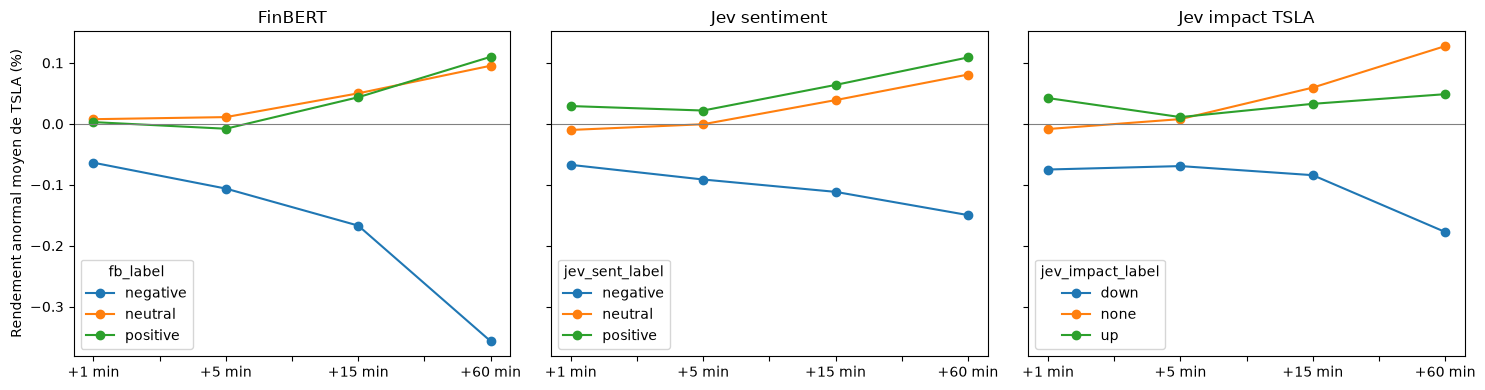

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (model, (col, _)) in zip(axes, CALLS.items()):
    means = ev.groupby(col)[[f"ar_{h}m" for h in HORIZONS]].mean() * 100
    means.columns = [f"+{h} min" for h in HORIZONS]
    means.T.plot(ax=ax, marker="o", title=model)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_ylabel("Rendement anormal moyen de TSLA (%)")
plt.tight_layout()
plt.show()
ev.groupby("jev_impact_label")[[f"ar_{h}m" for h in HORIZONS]].agg(["mean", "count"]).style.format("{:.4f}")

## 5. Latence et coût

La latence compte directement pour l'hypothèse du projet (réagir avant les humains).
On mesure le temps pour classer **un seul** post, comme en conditions réelles, sur 20 posts.

In [12]:
sample = df.clean_text.sample(20, random_state=0).tolist()

sentiment.finbert_classify(sample[:2])  # premier appel : chargement du modèle, hors mesure
finbert_lat = [sentiment.finbert_classify([t]).latency_s.iloc[0] for t in sample]
jev_lat = sentiment.jev_classify(sample, max_workers=1).latency_s

jev_cost = jev.input_tokens.sum() / 1e6 * sentiment.JEV_USD_PER_M_INPUT_TOKENS
pd.DataFrame({
    "latence médiane pour 1 post (s)": [np.median(finbert_lat), jev_lat.median()],
    "latence max (s)": [np.max(finbert_lat), jev_lat.max()],
    f"coût total pour {len(jev)} posts ($)": [0.0, jev_cost],
}, index=["FinBERT (CPU local)", "Jev (API)"]).round(4)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,latence médiane pour 1 post (s),latence max (s),coût total pour 2894 posts ($)
FinBERT (CPU local),0.0200,0.0268,0.0000
Jev (API),0.2405,0.3217,0.0571


## 6. Conclusions (à rédiger)

Questions pour guider l'interprétation :
- Les deux modèles sont-ils d'accord ? Sur quels types de posts divergent-ils (ironie, mèmes, réponses courtes) ?
- Un des scores annonce-t-il la réaction de TSLA mieux que le hasard, et à quel horizon ?
  Si oui, l'effet est-il assez grand pour couvrir des frais de transaction ?
- La question `impact` de Jev, spécifique à TSLA, fait-elle mieux que la question générique `sentiment` ?
- Le filtre de pertinence de Jev améliore-t-il les résultats ?
- Un bon résultat de Jev pourrait-il venir d'une fuite d'information (connaissance des événements a posteriori) ?
- La latence de chaque modèle est-elle compatible avec une réaction « avant les humains » ?